Building a Fully Connected Network (FCN) for
Devnagari Digit Classification.



Task 1: Data Preparation

In [2]:
from google.colab import files
import zipfile
import os
if not os.path.exists("dataset"):
    os.makedirs("dataset")

print("upload zipped dataset folder here:")
uploaded = files.upload()

for fn in uploaded.keys():
    print(f"User uploaded file \"{fn}\"")
    if fn.endswith(".zip"):
        with zipfile.ZipFile(fn, 'r') as zip_ref:
            zip_ref.extractall("dataset/")
        print(f"Successfully extracted {fn} to 'dataset/'")
        os.remove(fn)
    else:
        print(f"Skipping non-zip file: {fn}")
print("Dataset upload and extraction complete.")

upload zipped dataset folder here:


Saving Copy of devnagari digit.zip to Copy of devnagari digit.zip
User uploaded file "Copy of devnagari digit.zip"
Successfully extracted Copy of devnagari digit.zip to 'dataset/'
Dataset upload and extraction complete.


In [3]:
# !ls -R dataset/

In [4]:
import os
import numpy as np
from PIL import Image
from tensorflow.keras.utils import to_categorical

train_dir = '/content/dataset/DevanagariHandwrittenDigitDataset/Train'
test_dir = '/content/dataset/DevanagariHandwrittenDigitDataset/Test'

def load_dataset(base_path):
    images = []
    labels = []

    # sort folders
    folders = sorted(os.listdir(base_path))
    for folder_name in folders:
        folder_path = os.path.join(base_path, folder_name)
        if os.path.isdir(folder_path):
            label = int(folder_name.split('_')[-1])
            for file_name in os.listdir(folder_path):
                file_path = os.path.join(folder_path, file_name)

                try:
                    img = Image.open(file_path).convert('L')
                    img = img.resize((28, 28))
                    img_array = np.array(img) / 255.0
                    images.append(img_array)
                    labels.append(label)
                except Exception as e:
                    continue
    return np.array(images), np.array(labels)
print("Loading Training Data...")
X_train, y_train_raw = load_dataset(train_dir)

print("Loading Testing Data...")
X_test, y_test_raw = load_dataset(test_dir)

#one hot encoding for multi class classification
y_train = to_categorical(y_train_raw, num_classes=10)
y_test = to_categorical(y_test_raw, num_classes=10)

print("-" * 30)
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print("Data Preparation Complete.")

Loading Training Data...
Loading Testing Data...
------------------------------
X_train shape: (17000, 28, 28)
y_train shape: (17000, 10)
Data Preparation Complete.


In [ ]:
print("Max pixel value:", X_train.max())
print("Image dimensions:", X_train.shape[1:])
print("Example label (One-Hot):", y_train[0])


Max pixel value: 1.0
Image dimensions: (28, 28)
Example label (One-Hot): [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


Task 2: Build the FCN Model

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

#create a sequential model
model = Sequential()

#this converts the 28x28 image into a 1D vector of 784 neurons
model.add(Flatten(input_shape=(28, 28)))

#1st hidden layers as specifie, 1st hidden layer 64 neurons, sigmoid activation
model.add(Dense(64, activation='sigmoid'))

#2nd hidden layer: 128 neurons, sigmoid activation
model.add(Dense(128, activation='sigmoid'))

#3rd hidden layer: 256 neurons, sigmoid activation
model.add(Dense(256, activation='sigmoid'))

#add the output layer
model.add(Dense(10, activation='softmax'))
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,154 (367.79 KB)

 Trainable params: 94,154 (367.79 KB)

 Non-trainable params: 0 (0.00 B)

Task 3: Compile the Model

In [8]:
#Compiling the Model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print("Model compilation complete.")

Model compilation complete.


Task 4: Train the Model

In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.2, #20% training data used for validation
    verbose=1
)

Epoch 1/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.4949 - loss: 1.6083 - val_accuracy: 0.0000e+00 - val_loss: 7.1244
Epoch 2/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8576 - loss: 0.4908 - val_accuracy: 0.0000e+00 - val_loss: 8.6540
Epoch 3/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9240 - loss: 0.2656 - val_accuracy: 0.0000e+00 - val_loss: 9.4006
Epoch 4/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9446 - loss: 0.1896 - val_accuracy: 0.0000e+00 - val_loss: 9.8843
Epoch 5/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9565 - loss: 0.1504 - val_accuracy: 0.0000e+00 - val_loss: 10.1314
Epoch 6/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9643 - loss: 0.1220 - val_accuracy: 0.0000e+00 - val_loss: 10.2375
Epoch 7/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9724 - loss: 0.1012 - val_accuracy: 0.0000e+00 - val_loss: 10.4115
Epoch 8/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9758 -

Task 5: Evaluate the Model

In [13]:
#this returns the loss value and the metrics (accuracy) specified during compilation
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 2.5161
Test Accuracy: 78.67%


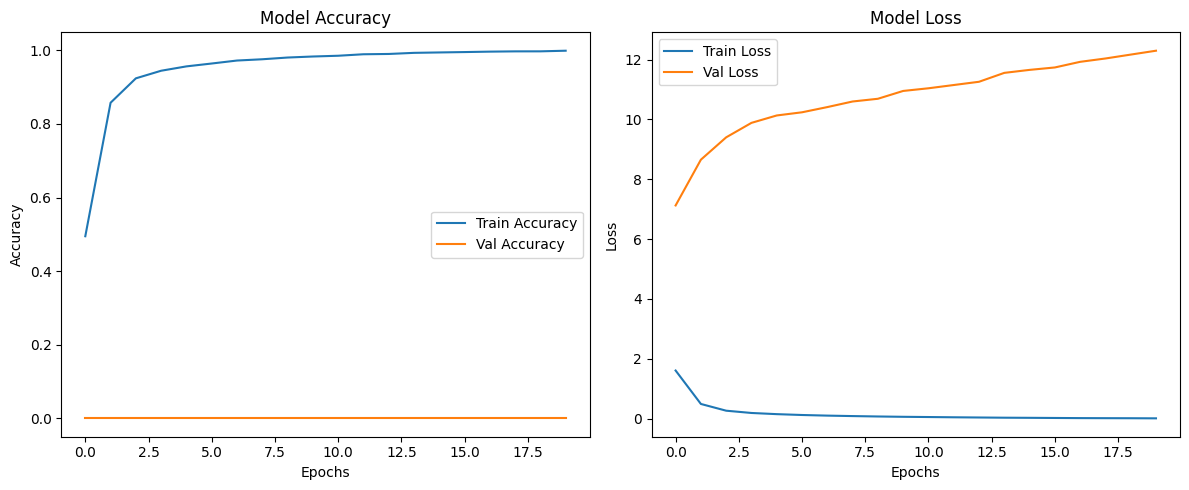

In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Task 6: Save and Load the Model

In [15]:

#saving the trained model to an .h5 file which contains the architecture, weights and training configuration
model.save('devnagari_digit_model.h5')
print("Model saved successfully as 'devnagari_digit_model.h5'")

from tensorflow.keras.models import load_model
loaded_model = load_model('devnagari_digit_model.h5')
print("Model loaded successfully.")

#re evaluating the loaded model's performance on the test set
loss, accuracy = loaded_model.evaluate(X_test, y_test, verbose=0)

print(f"Restored Model Accuracy: {accuracy * 100:.2f}%")
print(f"Restored Model Loss:     {loss:.4f}")

Model saved successfully as 'devnagari_digit_model.h5'
Model loaded successfully.
Restored Model Accuracy: 78.67%
Restored Model Loss:     2.5161


Task 7:
Making Predictions


94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


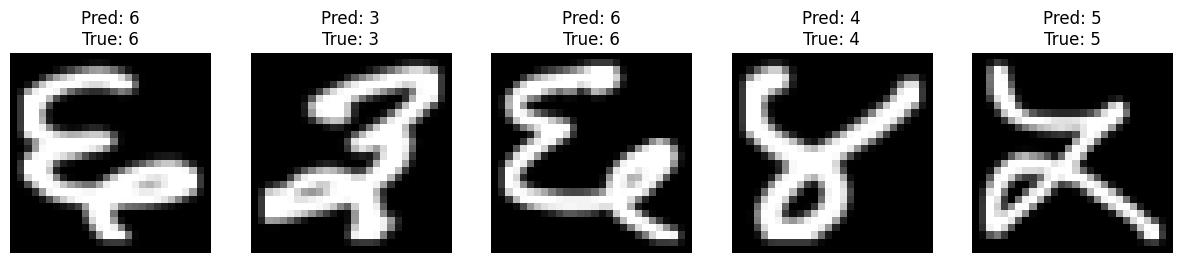

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#use model.predict() on the test set
predictions = model.predict(X_test)
#convert predicted probabilities to digit labels using np.argmax()
predicted_labels = np.argmax(predictions, axis=1)

#convert one-hot encoded ground truth back to integer labels for comparison
true_labels = np.argmax(y_test, axis=1)

#Displaying 5 random images from the test set with their predicted vs actual labels
plt.figure(figsize=(15, 5))
for i in range(5):
    index = np.random.randint(0, len(X_test))
    plt.subplot(1, 5, i+1)
    plt.imshow(X_test[index], cmap='gray')
    plt.title(f"Pred: {predicted_labels[index]}\nTrue: {true_labels[index]}")
    plt.axis('off')
plt.show()

In [ ]:
from google.colab import files
files.download('devnagari_digit_model.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import h5py
file_path = 'devnagari_digit_model.h5'

with h5py.File(file_path, 'r') as f:
    print("Top level groups in the H5 file:", list(f.keys()))
    if 'model_config' in f.attrs:
        print("\n Model Architecture (JSON)")
        print(f.attrs['model_config'])

    print("\n Layers and Weights Shapes")
    def print_structure(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"Dataset: {name} | Shape: {obj.shape}")
    f.visititems(print_structure)

Top level groups in the H5 file: ['model_weights', 'optimizer_weights']

 Model Architecture (JSON)
{"class_name": "Sequential", "config": {"name": "sequential", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "layers": [{"class_name": "InputLayer", "config": {"batch_shape": [null, 28, 28], "dtype": "float32", "sparse": false, "ragged": false, "name": "input_layer", "optional": false}}, {"class_name": "Flatten", "config": {"name": "flatten", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "data_format": "channels_last"}}, {"class_name": "Dense", "config": {"name": "dense", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "units": 64, "activation": "sigmoid", "use_bias": true, "kernel_initializer": {"module": "keras.initializers", "cl